# Black-box surrogate for the heat benchmark — the extrapolation cliff

Learn the temperature field directly from **solver data**, with no equation. We run the
Chapter-1 finite-difference heat solver on a unit square (hot left/right edges, cold
top/bottom) for a range of thermal diffusivities $\alpha$, sample the field at a fixed time
$t^*$, and train an MLP
$$\hat T_\theta(x,y,\alpha)\approx T(x,y,t^*;\alpha).$$
Inside the training band of $\alpha$ the surrogate is excellent; **outside it the error explodes**
— the black box has no governing equation to carry it, and nothing in the data tells it how the
field depends on diffusivity.

**The ground truth.** The benchmark solves the source-free 2-D heat equation
$$ \frac{\partial T}{\partial t} = \alpha\,\nabla^2 T $$
by explicit FTCS (central differences in space, forward Euler in time) on a $41\times41$ grid:
$$ T^{n+1}_{i,j} = T^{n}_{i,j} + \alpha\,\Delta t\left[
   \frac{T_{i+1,j}-2T_{i,j}+T_{i-1,j}}{\Delta x^2}
 + \frac{T_{i,j+1}-2T_{i,j}+T_{i,j-1}}{\Delta y^2}\right]. $$
**BC (Dirichlet):** hot left and right edges $T=1$, cold top and bottom edges $T=0$.
**IC:** $T\equiv 0$ in the interior. **Evaluation time:** $t^*=800\ \mathrm{s}$ (still transient).
**Swept parameter and split:** the thermal diffusivity $\alpha$ is the axis the surrogate must
generalize across, so the split is made along it. Training runs at
$\alpha\in\{3,4,5,7,8\}\times10^{-5}$; a validation run at $\alpha=6\times10^{-5}$ (inside the
band, used only to choose when to stop training); an in-range test run at
$\alpha=6.5\times10^{-5}$ that measures **interpolation**; and two out-of-range test runs at
$\alpha=1\times10^{-5}$ and $1.7\times10^{-4}$ that measure **extrapolation**.

one solver run per alpha, 1681 rows (x, y, alpha) -> T each
rows  train=8405  validation=1681  test-in=1681  test-out=3362


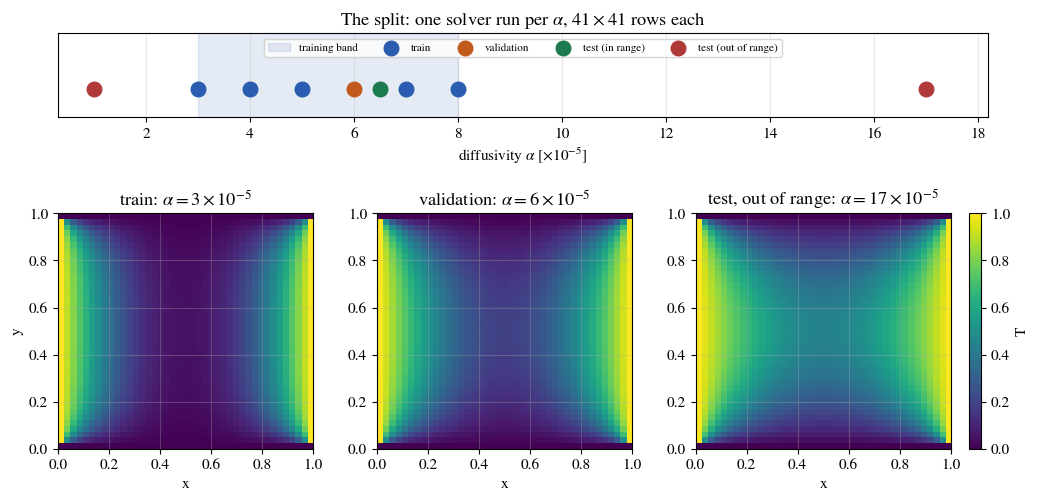

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))
import time, functools
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.nets import MLP
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.benchmarks.heat import HeatProblem, solve
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..','figures')); os.makedirs(FIG, exist_ok=True)

# --- ground truth: the real 2-D heat solver, parametrized by diffusivity alpha
NX = 41; TSTAR = 800.0                       # evaluation time (transient regime)
x = np.linspace(0, 1, NX); y = np.linspace(0, 1, NX)
Xg, Yg = np.meshgrid(x, y, indexing='ij')

@functools.lru_cache(maxsize=None)
def _field(a):
    _, _, T = solve(HeatProblem(nx=NX, ny=NX, alpha=a), t_end=TSTAR)
    return T

def field(a):
    "Solver temperature field T(x, y; alpha=a) at t = TSTAR (cached per alpha)."
    return _field(float(a))

# --- the split, along the axis we must generalize across: the diffusivity -------
A_TRAIN    = np.array([3, 4, 5, 7, 8]) * 1e-5     # fit the parameters
A_VAL      = 6.0e-5                               # inside the band: choose when to stop
A_TEST_IN  = 6.5e-5                               # inside the band, never seen: interpolation
A_TEST_OUT = np.array([1.0e-5, 1.7e-4])           # outside the band: extrapolation
A_LO, A_HI = 3e-5, 8e-5                           # the training band
SPLIT = [('train', A_TRAIN, 'C0'), ('validation', [A_VAL], 'C1'),
         ('test (in range)', [A_TEST_IN], 'C2'), ('test (out of range)', A_TEST_OUT, 'C3')]
print('one solver run per alpha, %d rows (x, y, alpha) -> T each' % (NX*NX))
print('rows  train=%d  validation=%d  test-in=%d  test-out=%d'
      % (len(A_TRAIN)*NX*NX, NX*NX, NX*NX, len(A_TEST_OUT)*NX*NX))

def plot_ddm_heat_split():
    fig = plt.figure(figsize=(12, 5.4))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 2.8], hspace=0.6, wspace=0.25)
    ax = fig.add_subplot(gs[0, :])
    ax.axvspan(A_LO*1e5, A_HI*1e5, color='C0', alpha=0.12, label='training band')
    for tag, avals, c in SPLIT:
        ax.scatter(np.array(avals)*1e5, np.zeros(len(avals)), s=110, color=c, zorder=3, label=tag)
    ax.set(xlim=(0.3, 18.2), ylim=(-1.2, 2.4), yticks=[], xlabel='diffusivity $\\alpha$ $[\\times10^{-5}]$',
           title='The split: one solver run per $\\alpha$, $41\\times41$ rows each')
    ax.legend(ncol=5, fontsize=8, loc='upper center')
    for j, (a, tag) in enumerate([(A_TRAIN[0], 'train'), (A_VAL, 'validation'), (A_TEST_OUT[1], 'test, out of range')]):
        axf = fig.add_subplot(gs[1, j])
        im = axf.imshow(field(a).T, origin='lower', extent=[0, 1, 0, 1], vmin=0, vmax=1, cmap='viridis', aspect='auto')
        axf.set(title=f'{tag}: $\\alpha={a*1e5:.0f}\\times10^{{-5}}$', xlabel='x', ylabel='y' if j == 0 else '')
    fig.colorbar(im, ax=fig.axes[1:], fraction=0.02, pad=0.02, label='T')

save_dual(plot_ddm_heat_split, 'ddm_heat_split', FIG); plt.show()

The prints confirm the budget: **nine solver runs of 1,681 rows each — 8,405 training rows from five diffusivities, 1,681 validation rows, 1,681 in-range test rows and 3,362 out-of-range test rows**. The data card shows the split on the $\alpha$ axis (top) and three of the fields (bottom): a training run at $\alpha = 3\times10^{-5}$, the validation run at $6\times10^{-5}$, and the out-of-range test at $17\times10^{-5}$. Every panel has the same hot left/right edges ($T=1$) and cold top/bottom edges ($T=0$), but $\alpha$ controls how far that boundary heat has soaked inward by $t^*=800\ \mathrm{s}$: at $3\times10^{-5}$ the interior is still mostly cold with a narrow warm collar at the side walls, at $17\times10^{-5}$ the warm front has pushed well past the centre. This genuine variation across $\alpha$ is what makes interpolation non-trivial and extrapolation meaningful.

## Train the surrogate, then sweep $\alpha$: the cliff

The MLP maps $(x,y,\alpha)\to T$ and is trained **only** on the five training runs. Architecture
`MLP([3, 96, 96, 96, 1])` (three hidden layers of 96 units); the inputs $(x,y,\alpha)$ and the
target $T$ are standardized **on the training rows only**, and we minimize the mean-squared error
$$ \mathcal L(\theta)=\frac1N\sum_{i}\big(\hat T_\theta(x_i,y_i,\alpha_i)-T_i\big)^2 $$
over the 8,405 training rows with up to 8000 full-batch Adam steps (`lr=2e-3`), keeping the
parameters with the **lowest validation loss** (checked every 100 steps). The three held-out sets
are then each scored once: validation, in-range test ($\alpha=6.5\times10^{-5}$) and the two
out-of-range tests. We also sweep $\alpha$ across `linspace(1e-5, 1.8e-4, 40)` — from well below to
well above the band — and measure the field RMSE against the solver at each value, and compare
centerline profiles ($T$ at $y=0.5$) at the in-range and the far out-of-range test diffusivity.
Inside the band the error is tiny; outside it, it climbs sharply.

Three further things are measured, because the slides quote them: the **cost** of one surrogate
evaluation against one solver run; a **four-member deep ensemble** of the same surrogate (seeds
0–3), whose spread across $\alpha$ is the epistemic-uncertainty signal from the uncertainty
notebook, drawn as the middle panel; and two pieces of **physics the surrogate was never told** —
the Dirichlet boundary values and the mirror symmetry of the field in $x$ — checked on its output
at the interpolation and the extrapolation diffusivity.

final train loss 1.89e-05   best validation loss 2.23e-05 at step 8000
field RMSE  validation (6.0)=1.386e-03   test-in (6.5)=1.375e-03   test-out (1.0)=5.384e-02   test-out (17)=6.844e-02
extrapolation error is 50x (high) / 39x (low) the interpolation error
one solver run 6 ms   one surrogate evaluation 1.3 ms   speed-up 4x


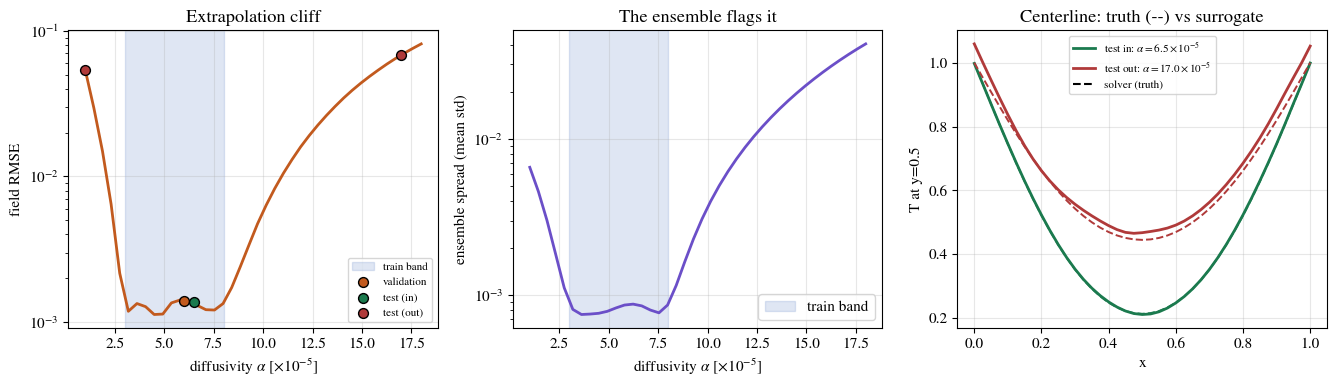

field RMSE  in-band mean=1.272e-03   sweep ends: low=5.384e-02  high=8.144e-02
ensemble spread  in-band=8.098e-04   out-of-band=1.402e-02   ratio 17x
test in : max boundary-condition violation 0.007   max mirror-asymmetry 0.007
test out: max boundary-condition violation 0.469   max mirror-asymmetry 0.408


In [2]:
def rows(alphas):
    "Stack (x, y, alpha) -> T rows for the given solver runs."
    X, Y = [], []
    for a in np.atleast_1d(alphas):
        X.append(np.c_[Xg.ravel(), Yg.ravel(), np.full(Xg.size, float(a))]); Y.append(field(a).ravel())
    return np.vstack(X), np.concatenate(Y).reshape(-1, 1)
Xtr, Ytr = rows(A_TRAIN); Xva, Yva = rows(A_VAL)
Xm, Xs = Xtr.mean(0), Xtr.std(0); Ym, Ys = Ytr.mean(), Ytr.std()        # standardize on the training rows only
norm = lambda X: torch.tensor((X - Xm) / Xs)
Xt, Yt = norm(Xtr), torch.tensor((Ytr - Ym) / Ys); Xv, Yv = norm(Xva), torch.tensor((Yva - Ym) / Ys)

def train_surrogate(seed, steps=8000, every=100):
    "Full-batch Adam; keep the parameters with the lowest validation loss."
    torch.manual_seed(seed); m = MLP([3, 96, 96, 96, 1]); opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    best, best_step, best_state = np.inf, 0, None
    for step in range(1, steps + 1):
        opt.zero_grad(); loss = ((m(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
        if step % every == 0:
            with torch.no_grad(): lva = float(((m(Xv) - Yv)**2).mean())
            if lva < best: best, best_step, best_state = lva, step, {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state)
    return m, float(loss.detach()), best, best_step

net, final_loss, best_val, best_step = train_surrogate(0)
print(f'final train loss {final_loss:.2e}   best validation loss {best_val:.2e} at step {best_step}')

def predict_field(a, model=None):
    P = np.c_[Xg.ravel(), Yg.ravel(), np.full(Xg.size, float(a))]
    with torch.no_grad():
        out = (model or net)(norm(P)).numpy().ravel() * Ys + Ym
    return out.reshape(NX, NX)
rmse_at = lambda a, model=None: float(np.sqrt(np.mean((predict_field(a, model) - field(a))**2)))

# --- the held-out sets, each touched once --------------------------------------
r_val, r_in = rmse_at(A_VAL), rmse_at(A_TEST_IN)
r_out_lo, r_out_hi = rmse_at(A_TEST_OUT[0]), rmse_at(A_TEST_OUT[1])
print(f'field RMSE  validation (6.0)={r_val:.3e}   test-in (6.5)={r_in:.3e}   '
      f'test-out (1.0)={r_out_lo:.3e}   test-out (17)={r_out_hi:.3e}')
print(f'extrapolation error is {r_out_hi/r_in:.0f}x (high) / {r_out_lo/r_in:.0f}x (low) the interpolation error')

# --- measured: one solver run vs one surrogate evaluation ----------------------
t0 = time.perf_counter(); solve(HeatProblem(nx=NX, ny=NX, alpha=6.5e-5), t_end=TSTAR); t_solver = time.perf_counter() - t0
t0 = time.perf_counter(); predict_field(6.5e-5); t_net = time.perf_counter() - t0
print(f'one solver run {t_solver*1e3:.0f} ms   one surrogate evaluation {t_net*1e3:.1f} ms   speed-up {t_solver/t_net:.0f}x')

# --- a deep ensemble of the same surrogate: does its spread flag the cliff? -----
ens = [net] + [train_surrogate(s)[0] for s in (1, 2, 3)]
def spread(a):
    "Mean over the field of the ensemble standard deviation at diffusivity a."
    return np.stack([predict_field(a, m) for m in ens]).std(0).mean()

# --- sweep alpha across and beyond the band: the extrapolation cliff -----------
a_sweep = np.linspace(1e-5, 1.8e-4, 40)
rmse = np.array([rmse_at(a) for a in a_sweep]); sprd = np.array([spread(a) for a in a_sweep])
inband = (a_sweep >= A_LO) & (a_sweep <= A_HI)
a_interp, a_extrap = A_TEST_IN, A_TEST_OUT[1]

def plot_ddm_heat_cliff():
    fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.0))
    for a_ in ax[:2]: a_.axvspan(A_LO*1e5, A_HI*1e5, color='C0', alpha=0.15, label='train band')
    ax[0].semilogy(a_sweep*1e5, rmse, 'C1', lw=2)
    for a, c, tag in [(A_VAL, 'C1', 'validation'), (A_TEST_IN, 'C2', 'test (in)'),
                      (A_TEST_OUT[0], 'C3', 'test (out)'), (A_TEST_OUT[1], 'C3', None)]:
        ax[0].scatter([a*1e5], [rmse_at(a)], color=c, s=50, zorder=4, edgecolor=fg(), label=tag)
    ax[0].set(xlabel='diffusivity $\\alpha$ $[\\times10^{-5}]$', ylabel='field RMSE',
              title='Extrapolation cliff'); ax[0].legend(fontsize=8)
    ax[1].semilogy(a_sweep*1e5, sprd, 'C4', lw=2)
    ax[1].set(xlabel='diffusivity $\\alpha$ $[\\times10^{-5}]$', ylabel='ensemble spread (mean std)',
              title='The ensemble flags it'); ax[1].legend()
    mid = NX // 2
    for a, c, tag in [(a_interp, 'C2', 'test in'), (a_extrap, 'C3', 'test out')]:
        Tt = field(a); Tp = predict_field(a)
        ax[2].plot(x, Tt[:, mid], '--', color=c, lw=1.4)
        ax[2].plot(x, Tp[:, mid], color=c, lw=2, label=f'{tag}: $\\alpha={a*1e5:.1f}\\times10^{{-5}}$')
    ax[2].plot([], [], '--', color=fg(), label='solver (truth)')
    ax[2].set(xlabel='x', ylabel='T at y=0.5', title='Centerline: truth (--) vs surrogate'); ax[2].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_ddm_heat_cliff, 'ddm_heat_cliff', FIG); plt.show()
r_band = rmse[inband].mean()
print(f'field RMSE  in-band mean={r_band:.3e}   sweep ends: low={rmse[0]:.3e}  high={rmse[-1]:.3e}')
s_in, s_out = sprd[inband].mean(), sprd[~inband].mean()
print(f'ensemble spread  in-band={s_in:.3e}   out-of-band={s_out:.3e}   ratio {s_out/s_in:.0f}x')
assert r_out_hi > 8*r_in and r_out_lo > 8*r_in     # error explodes outside the band
assert s_out > 3*s_in                              # ...and the ensemble spread says so

# --- measured: physics the surrogate was never told, checked on its output -------
def physics_check(a):
    Tp = predict_field(a)
    bc  = max(np.abs(Tp[0, 1:-1] - 1).max(), np.abs(Tp[-1, 1:-1] - 1).max(),   # hot left/right
              np.abs(Tp[1:-1, 0]).max(),     np.abs(Tp[1:-1, -1]).max())       # cold top/bottom
    sym = np.abs(Tp - Tp[::-1, :]).max()                                       # mirror symmetry in x
    return bc, sym
for a, tag in [(a_interp, 'test in '), (a_extrap, 'test out')]:
    bc, sym = physics_check(a)
    print(f'{tag}: max boundary-condition violation {bc:.3f}   max mirror-asymmetry {sym:.3f}')

Validation never turned upward (best at step 8000), so the checkpoint is the last one, and the three held-out numbers make the cliff quantitative: **validation RMSE $1.39\times10^{-3}$ and in-range test RMSE $1.38\times10^{-3}$** — two runs inside the band, agreeing as they should — versus **$5.4\times10^{-2}$ and $6.8\times10^{-2}$ at the two out-of-range diffusivities**, a **$39\times$–$50\times$** jump the moment $\alpha$ leaves the training range, so the `assert` that out-of-range error exceeds $8\times$ the in-range error passes easily. The left panel draws this as a **U-shaped cliff**: RMSE is flat near $10^{-3}$ across the shaded band (validation and in-range test sit on the floor) and rises steeply on both sides to the red out-of-range points. The right panel makes it physical — the green **in-range** centerline lies right on the dashed solver truth, while the red **out-of-range** curve ($\alpha=17\times10^{-5}$) visibly pulls off its own truth near the centre.

Three more measured facts. A **surrogate evaluation costs 1.3 ms against 6 ms for a solver run —
a 4× speed-up** on this small $41\times41$ explicit problem; the gap widens with grid size and
integration time, but on this benchmark the cost argument alone is modest. The **ensemble spread**
(middle panel) rises in step with the error: mean std $8.1\times10^{-4}$ in-band against
$1.4\times10^{-2}$ outside, **17×**, so a four-member ensemble flags the cliff without ever seeing
the solver truth, and the `assert` on that ratio passes. And the surrogate breaks physics it was
never told: at the in-range test $\alpha$ its boundary values are within $0.007$ of the Dirichlet
data and its field is mirror-symmetric to $0.007$; at the out-of-range $\alpha$ the
**boundary-condition violation is 0.47** on a unit temperature scale and the **asymmetry is 0.41**
— the hot edges are no longer hot and the field is no longer symmetric, with nothing in the model
to object.

**Lesson.** The surrogate is fast and accurate *inside* its training distribution of $\alpha$ but
has no mechanism to extrapolate — the field it predicts for an unseen diffusivity drifts away from
the solver. There is no conservation law or governing equation to anchor it. What is missing is not
more solver runs inside the band but the equation itself --- structure the data cannot supply.
A single network gives no warning; an ensemble of four does — its spread grows 17-fold outside
the band — and that is the cheapest safeguard a data-only model has.